## Dataset
Link : https://www.kaggle.com/datasets/neharoychoudhury/credit-card-fraud-data/data

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from yellowbrick.cluster import KElbowVisualizer
from matplotlib.colors import ListedColormap
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.pipeline import Pipeline

from sklearn.model_selection import train_test_split,GridSearchCV, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

# 7. Metrics
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 8. Ignore warnings
import warnings
warnings.filterwarnings('ignore')

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Load Dataset


In [4]:
df = pd.read_csv("/content/drive/MyDrive/SI DATA SCIENTIST CAKAP/fraud_data.csv")

In [5]:
df.head()

,trans_date_trans_time,merchant,category,amt,city,state,lat,long,city_pop,job,dob,trans_num,merch_lat,merch_long,is_fraud
0,04-01-2019 00:58,"""Stokes, Christiansen and Sipes""",grocery_net,14.37,Wales,AK,64.7556,-165.6723,145,"""Administrator, education""",09-11-1939,a3806e984cec6ac0096d8184c64ad3a1,65.654142,-164.722603,1
1,04-01-2019 15:06,Predovic Inc,shopping_net,966.11,Wales,AK,64.7556,-165.6723,145,"""Administrator, education""",09-11-1939,a59185fe1b9ccf21323f581d7477573f,65.468863,-165.473127,1
2,04-01-2019 22:37,Wisozk and Sons,misc_pos,49.61,Wales,AK,64.7556,-165.6723,145,"""Administrator, education""",09-11-1939,86ba3a888b42cd3925881fa34177b4e0,65.347667,-165.914542,1
3,04-01-2019 23:06,Murray-Smitham,grocery_pos,295.26,Wales,AK,64.7556,-165.6723,145,"""Administrator, education""",09-11-1939,3a068fe1d856f0ecedbed33e4b5f4496,64.445035,-166.080207,1
4,04-01-2019 23:59,Friesen Lt,health_fitness,18.17,Wales,AK,64.7556,-165.6723,145,"""Administrator, education""",09-11-1939,891cdd1191028759dc20dc224347a0ff,65.447094,-165.446843,1


## Data Understanding

In [6]:
df.shape

(14446, 15)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14446 entries, 0 to 14445
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   trans_date_trans_time  14446 non-null  object 
 1   merchant               14446 non-null  object 
 2   category               14446 non-null  object 
 3   amt                    14446 non-null  float64
 4   city                   14446 non-null  object 
 5   state                  14446 non-null  object 
 6   lat                    14446 non-null  float64
 7   long                   14446 non-null  float64
 8   city_pop               14446 non-null  int64  
 9   job                    14446 non-null  object 
 10  dob                    14446 non-null  object 
 11  trans_num              14446 non-null  object 
 12  merch_lat              14446 non-null  float64
 13  merch_long             14446 non-null  float64
 14  is_fraud               14446 non-null  object 
dtypes:

In [8]:
df.describe()

,amt,lat,long,city_pop,merch_lat,merch_long
count,14446.000000,14446.000000,14446.000000,1.444600e+04,14446.000000,14446.000000
mean,124.430073,39.787692,-110.874225,1.065370e+05,39.787991,-110.874892
std,231.352587,5.317039,12.985813,2.902916e+05,5.360593,12.995596
min,1.000000,20.027100,-165.672300,4.600000e+01,19.032689,-166.670685
25%,12.080000,36.715400,-120.415800,4.930000e+02,36.794655,-120.146253
50%,51.520000,39.666200,-111.098500,1.645000e+03,39.620953,-111.192629
75%,101.030000,41.940400,-101.136000,3.543900e+04,42.275740,-100.446822
max,3261.470000,66.693300,-89.628700,2.383912e+06,67.510267,-88.646366


In [9]:
# missing value
df.isna().sum()

,0
trans_date_trans_time,0
merchant,0
category,0
amt,0
city,0
state,0
lat,0
long,0
city_pop,0
job,0


## EDA

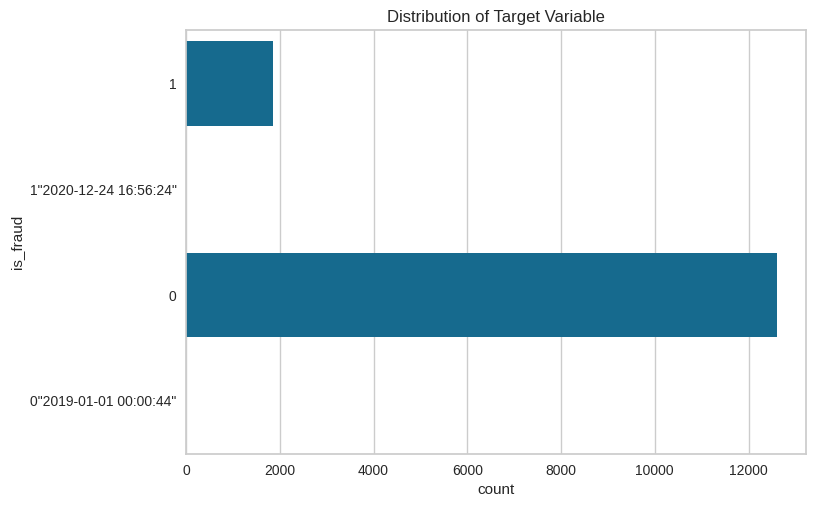

In [28]:
# distribution of is_fraud

sns.countplot(df['is_fraud'])
plt.title('Distribution of Target Variable')
plt.show()

<ipython-input-12-96caf4d93add>:7: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(df['state'], kde=True, color="#FF5733", palette=custom_colors)


<Axes: xlabel='state', ylabel='Count'>

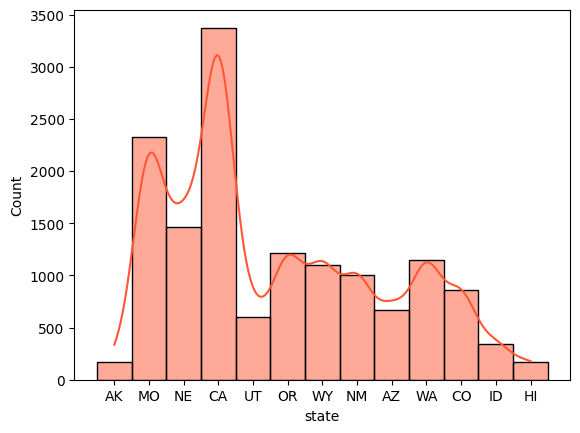

In [12]:
# distribution of state

# Define custom colors
custom_colors = ["#FF5733", "#3366FF", "#33FF57"]  # Example colors, you can adjust as needed

# Plot the histogram with custom colors
sns.histplot(df['state'], kde=True, color="#FF5733", palette=custom_colors)

Mean 124.43007337671327
Median 51.519999999999996
Mode 0    1.64
1    2.77
2    5.24
Name: amt, dtype: float64


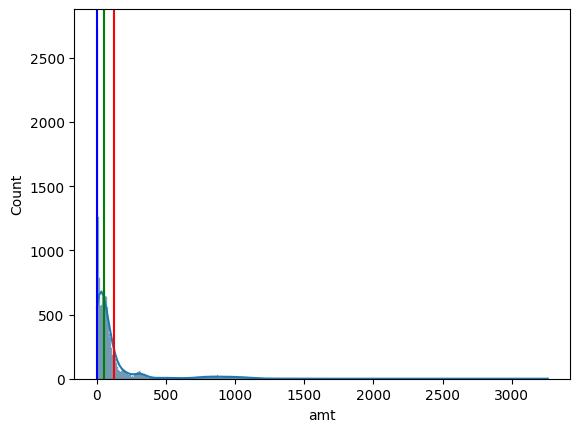

In [13]:
# Plot the mean, Median and mode of quality column using sns
sns.histplot(df['amt'], kde=True)
plt.axvline(df['amt'].mean(), color='Red')
plt.axvline(df['amt'].median(), color= 'Green')
plt.axvline(df['amt'].mode()[0], color='Blue')

# print the value of mean, median and mode of quality column
print('Mean', df['amt'].mean())
print('Median', df['amt'].median())
print('Mode', df['amt'].mode())

In [17]:
# plot the histogram of amt column using plotly and coloring this by is_fraud

fig = px.histogram(data_frame=df, x='amt', color= 'is_fraud')
fig.show()

In [23]:
# Menghitung nilai unik dalam kolom trans_date_trans_time
unique_trans_date_trans_time = df['trans_date_trans_time'].nunique()
print(f'Jumlah kartu unik: {unique_trans_date_trans_time}')

Jumlah kartu unik: 12126


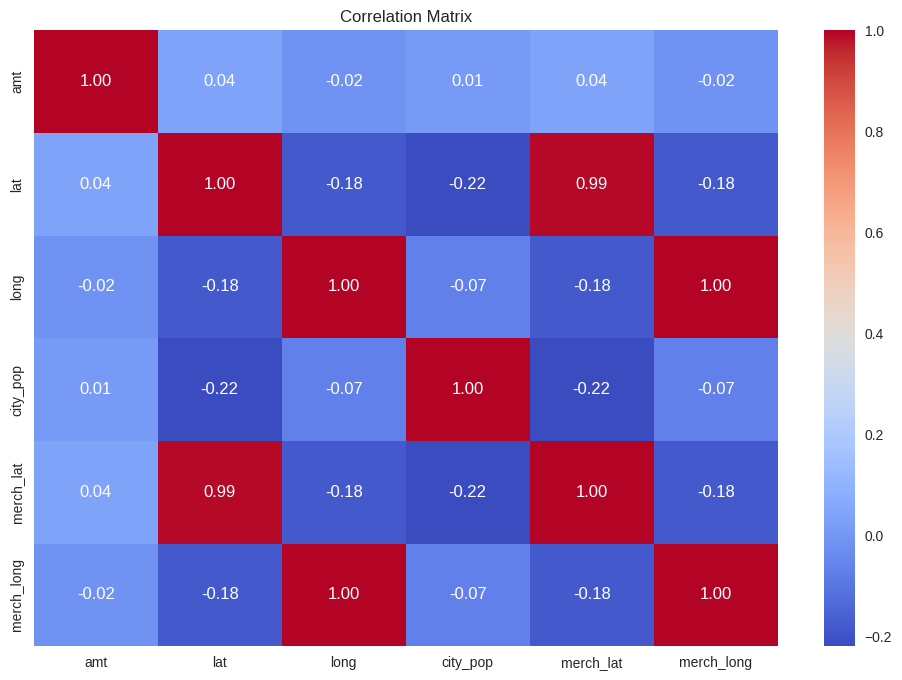

In [26]:
numerical_features = df.select_dtypes(include=['number']).columns
correlation = df[numerical_features].corr()

plt.figure(figsize=(12, 8))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

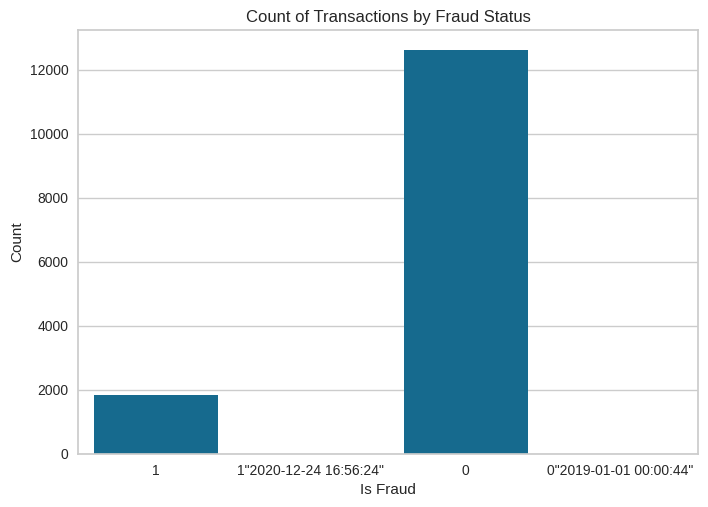

In [27]:
# Countplot untuk kolom is_fraud
sns.countplot(x='is_fraud', data=df)
plt.title('Count of Transactions by Fraud Status')
plt.xlabel('Is Fraud')
plt.ylabel('Count')
plt.show()

## Imbalance Case

In [63]:
# Periksa distribusi kelas pada kolom target
target_distribution = df['is_fraud'].value_counts(normalize=True) * 100
print("Distribusi Kelas dalam Status (%):\n", target_distribution)

Distribusi Kelas dalam Status (%):
 is_fraud
0.0    87.233453
1.0    12.766547
Name: proportion, dtype: float64


In [29]:
# Step 1: Separate majority and minority is_fraud
df_majority = df[df['is_fraud'] == 0]
df_minority = df[df['is_fraud'] == 1]

In [35]:
# Step 2: Upsample minority class
# Check if df_majority is empty before upsampling
from sklearn.utils import resample # Assuming you're using resample from scikit-learn
import pandas as pd

if len(df_majority) > 0:
    df_minority_upsampled = resample(df_minority,
                                     replace=True,     # Sample with replacement
                                     n_samples=len(df_majority), # Match majority class
                                     random_state=42)  # Seed for reproducibility
else:
    # Handle the case where df_majority is empty
    # For example, you could assign an empty DataFrame to df_minority_upsampled
    df_minority_upsampled = pd.DataFrame(columns=df_minority.columns)
    #Or raise an exception to stop if its unexpected

# Step 3: Combine majority class with upsampled minority class
df_upsampled = pd.concat([df_majority, df_minority_upsampled])

In [62]:
# Step 4: Check the class distribution
print("After Upsampling:")
print(df_upsampled['is_fraud'].value_counts())

After Upsampling:
is_fraud
0.0    12600
1.0    12600
Name: count, dtype: int64


## Modeling


In [48]:
# Convert is_fraud to numeric, forcing errors to NaN
df['is_fraud'] = pd.to_numeric(df['is_fraud'], errors='coerce')

# Drop rows with NaN in is_fraud
df = df.dropna(subset=['is_fraud'])

# Now filter again
df_majority = df[df['is_fraud'] == 0]
df_minority = df[df['is_fraud'] == 1]

# Check sizes
print(f'Jumlah baris dalam df_majority: {len(df_majority)}')
print(f'Jumlah baris dalam df_minority: {len(df_minority)}')

Jumlah baris dalam df_majority: 12600
Jumlah baris dalam df_minority: 1844


In [49]:
# Check the unique values in is_fraud
print("Unique values in is_fraud:", df['is_fraud'].unique())

# Convert is_fraud to numeric, forcing errors to NaN
df['is_fraud'] = pd.to_numeric(df['is_fraud'], errors='coerce')

# Drop rows with NaN in is_fraud
df = df.dropna(subset=['is_fraud'])

# Split into majority and minority classes
df_majority = df[df['is_fraud'] == 0]
df_minority = df[df['is_fraud'] == 1]

# Check sizes after filtering
print(f'Jumlah baris dalam df_majority: {len(df_majority)}')
print(f'Jumlah baris dalam df_minority: {len(df_minority)}')

# Print samples from both classes
print("Majority class samples:")
print(df_majority.head())
print("Minority class samples:")
print(df_minority.head())

# Perform upsampling if the minority class is not empty
if len(df_minority) > 0:
    df_minority_upsampled = resample(df_minority,
                                      replace=True,
                                      n_samples=len(df_majority),
                                      random_state=42)

    # Combine back to form a balanced dataset
    df_upsampled = pd.concat([df_majority, df_minority_upsampled])
    print(f'Jumlah baris dalam df_upsampled: {len(df_upsampled)}')
else:
    print("No samples in minority class to upsample.")

Unique values in is_fraud: [1. 0.]
Jumlah baris dalam df_majority: 12600
Jumlah baris dalam df_minority: 1844
Majority class samples:
     trans_date_trans_time                                merchant  \
1782      24-12-2020 16:58           "Hahn, Douglas and Schowalte"   
1783      24-12-2020 16:59                           Erdman-Durgan   
1784      24-12-2020 16:59         "Prosacco, Kreiger and Kovacek"   
1785      24-12-2020 16:59  "Romaguera, Cruickshank and Greenholt"   
1786      24-12-2020 17:00                      Spencer-Runolfsson   

            category     amt        city state      lat      long  city_pop  \
1782          travel  440.56   Meadville    MO  39.7795  -93.3014       964   
1783  health_fitness   60.39  Crownpoint    NM  35.7206 -108.0271      5662   
1784            home   16.13  Mound City    MO  40.1362  -95.2138      1631   
1785    shopping_net    6.70        Napa    CA  38.4549 -122.2564     94014   
1786        misc_pos   55.61   Hawthorne    CA  33

In [53]:
# 1. Identify columns with date/time strings:
datetime_cols = ['trans_date_trans_time']
for col in datetime_cols:
    # a. Convert to datetime objects
    df_upsampled[col] = pd.to_datetime(df_upsampled[col])
    # b. Extract numerical features (e.g., hour, day, month)
    df_upsampled[col + '_hour'] = df_upsampled[col].dt.hour
    df_upsampled[col + '_day'] = df_upsampled[col].dt.day
    df_upsampled[col + '_month'] = df_upsampled[col].dt.month
    # c. Drop the original datetime column
    df_upsampled = df_upsampled.drop(col, axis=1)

# 3. Handle other categorical features:
categorical_cols = df_upsampled.select_dtypes(include=['object']).columns
for col in categorical_cols:
    if col != 'is_fraud': # Exclude target variable
        le = LabelEncoder()
        df_upsampled[col] = le.fit_transform(df_upsampled[col])

In [57]:
# Split the data
X = df_upsampled.drop('is_fraud', axis=1)
y = df_upsampled['is_fraud']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [56]:
# Train a Random Forest Classifier
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [58]:
# Predictions
y_pred = model.predict(X_test)
y_pred_proba = model.predict_proba(X_test)[:, 1]

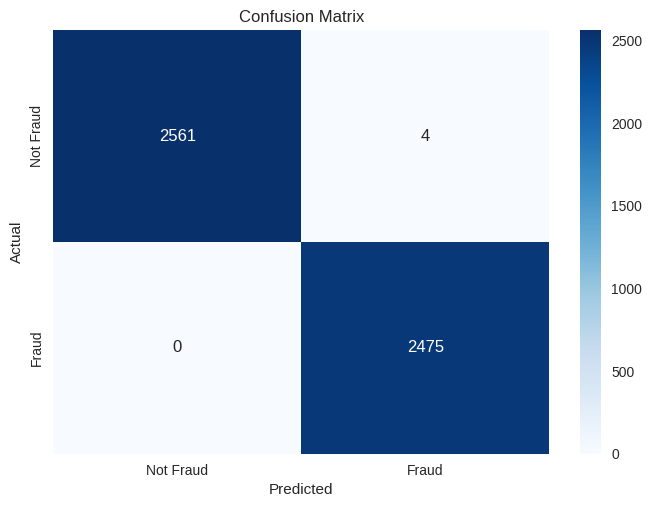

In [59]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Not Fraud', 'Fraud'], yticklabels=['Not Fraud', 'Fraud'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [60]:
# Classification Report
print("Classification Report:\n")
print(classification_report(y_test, y_pred))

Classification Report:

              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00      2565
         1.0       1.00      1.00      1.00      2475

    accuracy                           1.00      5040
   macro avg       1.00      1.00      1.00      5040
weighted avg       1.00      1.00      1.00      5040



Dari laporan klasifikasi ini, dapat dilihat bahwa model memiliki performa yang sangat baik dengan nilai precision, recall, dan F1-score semua bernilai 1.00 untuk kedua kelas. Ini menunjukkan bahwa model dapat memprediksi dengan akurat dan tidak menghasilkan kesalahan dalam klasifikasi baik untuk kelas mayoritas (0.0) maupun kelas minoritas (1.0).

In [61]:
# AUC-ROC Score
roc_auc = roc_auc_score(y_test, y_pred_proba)
print("ROC-AUC Score: ", roc_auc)

ROC-AUC Score:  0.9999995274381239


## Interpretasi Hasil:
1. Dengan upsampling, distribusi kelas menjadi seimbang, yang membantu model mempelajari pola dari kedua kelas secara setara.
2. Evaluasi dengan ROC-AUC menunjukkan kemampuan model untuk membedakan antara kelas positif dan negatif.Dengan ROC-AUC Score hampir mencapai 1.0 (0.9999), ini menandakan bahwa model sangat efektif dalam membedakan antara kelas positif dan negatif. Model memiliki kemampuan yang sangat baik untuk mengidentifikasi contoh dari kedua kelas.
3. Pada Classification Report, dapat dilihat bahwa model memiliki performa yang sangat baik dengan nilai precision, recall, dan F1-score semua bernilai 1.00 untuk kedua kelas. Ini menunjukkan bahwa model dapat memprediksi dengan akurat dan tidak menghasilkan kesalahan dalam klasifikasi baik untuk kelas mayoritas (0.0) maupun kelas minoritas (1.0).
